In [98]:
# Data handling
import pandas as pd
import numpy as np
import math

import re
import string
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from gensim.models import Word2Vec, FastText

from sklearn.metrics.pairwise import cosine_similarity
from scipy.spatial.distance import cosine

import matplotlib.pyplot as plt
import seaborn as sns

import os
import pickle
import joblib
import html
import unicodedata
import warnings
warnings.filterwarnings('ignore')

print("All libraries imported successfully!")

df = pd.read_csv("data/processed/cleaned_news_corpus.csv")

df = pd.read_csv("data/processed/cleaned_news_corpus.csv")

print("Dataset loaded successfully!")
print("Total articles:", len(df))
print("Dataset shape:", df.shape)

df.head()

All libraries imported successfully!
Dataset loaded successfully!
Total articles: 6298
Dataset shape: (6298, 8)


article_id  \
0        8476   
1       10294   
2        3608   
3       10142   
4         875   

                                                                                   title  \
0                                                           You Can Smell Hillary’s Fear   
1  Watch The Exact Moment Paul Ryan Committed Political Suicide At A Trump Rally (VIDEO)   
2                                            Kerry to go to Paris in gesture of sympathy   
3   Bernie supporters on Twitter erupt in anger against the DNC: 'We tried to warn you!'   
4                                       The Battle of New York: Why This Primary Matters   

                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                   

In [99]:
# Remove empty values
df = df.dropna(subset=['clean_text'])

# Convert cleaned text into a list
corpus = df['clean_text'].astype(str).tolist()

# Tokenize articles for Word2Vec and FastText
tokenized_corpus = [text.split() for text in corpus]

print("Total documents:", len(corpus))
print("Total tokenized documents:", len(tokenized_corpus))
print("\nFirst article:")
print(corpus[0][:500])

Total documents: 6298
Total tokenized documents: 6298

First article:
daniel greenfield shillman journalism fellow freedom center new york writer focusing radical islam final stretch election hillary rodham clinton gone war fbi word unprecedented thrown around often election ought retired still unprecedented nominee major political party go war fbi exactly hillary people done coma patient waking watching hour cnn hospital bed would assume fbi director james comey hillary opponent election fbi attack everyone obama cnn hillary people circulated letter attacking com


In [100]:
print("Empty documents:", sum(len(doc) == 0 for doc in tokenized_corpus))
print("Total words:", sum(len(doc) for doc in tokenized_corpus))
print("Vocabulary size:", len(set(word for doc in tokenized_corpus for word in doc)))

Empty documents: 0
Total words: 2740236
Vocabulary size: 55790


In [101]:
# Initialize Bag of Words vectorizer
bow_vectorizer = CountVectorizer(max_features=5000)

# Convert text into numerical representation
bow_matrix = bow_vectorizer.fit_transform(corpus)

print("Bag of Words completed!")
print("Number of documents:", bow_matrix.shape[0])
print("Number of features:", bow_matrix.shape[1])

Bag of Words completed!
Number of documents: 6298
Number of features: 5000


In [102]:
total_elements = bow_matrix.shape[0] * bow_matrix.shape[1]
nonzero_elements = bow_matrix.nnz
zero_elements = total_elements - nonzero_elements

sparsity = (zero_elements / total_elements) * 100

print("BoW Matrix Shape:", bow_matrix.shape)
print("Total Elements:", total_elements)
print("Non-zero Elements:", nonzero_elements)
print("Zero Elements:", zero_elements)
print("BoW Sparsity: {:.2f}%".format(sparsity))

BoW Matrix Shape: (6298, 5000)
Total Elements: 31490000
Non-zero Elements: 1375394
Zero Elements: 30114606
BoW Sparsity: 95.63%


In [103]:
# Get the words learned by the vectorizer
bow_vocabulary = bow_vectorizer.get_feature_names_out()

print("First 30 vocabulary words:")
print(bow_vocabulary[:30])

First 30 vocabulary words:
['abandon' 'abandoned' 'abc' 'abdullah' 'abedin' 'ability' 'able'
 'abortion' 'abroad' 'absence' 'absent' 'absentee' 'absolute' 'absolutely'
 'absurd' 'abuse' 'aca' 'academic' 'academy' 'accept' 'acceptable'
 'acceptance' 'accepted' 'accepting' 'access' 'accident' 'accompanied'
 'accomplish' 'accomplished' 'accomplishment']


In [104]:
# Convert sparse matrix into DataFrame for viewing
bow_df = pd.DataFrame(
    bow_matrix[:5].toarray(),
    columns=bow_vocabulary
)

bow_df

,abandon,abandoned,abc,abdullah,abedin,ability,able,abortion,abroad,absence,...,york,young,younger,youth,youtube,zero,zika,zionist,zone,zulu
0,0,0,0,0,1,0,0,0,0,0,...,2,0,0,0,0,0,0,0,0,0
1,0,0,1,0,0,0,0,0,0,0,...,0,0,0,0,0,1,0,0,0,0
2,0,0,0,0,0,0,0,0,1,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,1,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,5,1,0,0,0,0,0,0,0,0


In [105]:
# Initialize TF-IDF vectorizer
tfidf_vectorizer = TfidfVectorizer(max_features=5000)

# Convert text into TF-IDF numerical representation
tfidf_matrix = tfidf_vectorizer.fit_transform(corpus)

print("TF-IDF completed!")
print("Number of documents:", tfidf_matrix.shape[0])
print("Number of features:", tfidf_matrix.shape[1])

TF-IDF completed!
Number of documents: 6298
Number of features: 5000


In [106]:
# Select the first news article
article_index = 0

# Get TF-IDF scores for this article
article_scores = tfidf_matrix[article_index].toarray().flatten()

# Get the words and their scores
words = tfidf_vectorizer.get_feature_names_out()

tfidf_results = pd.DataFrame({
    'Word': words,
    'TF-IDF Score': article_scores
})

# Display highest-weight words
print("Top 10 High TF-IDF Words:")
print(tfidf_results.sort_values(
    by='TF-IDF Score', ascending=False
).head(10))

# Display common words with low weights
print("\nCommon words and their TF-IDF scores:")

common_words = ['said', 'people', 'one', 'year', 'would']

print(
    tfidf_results[tfidf_results['Word'].isin(common_words)]
    .sort_values(by='TF-IDF Score')
)

Top 10 High TF-IDF Words:
               Word  TF-IDF Score
1722            fbi      0.622463
837           comey      0.280709
2118        hillary      0.222835
794         clinton      0.214718
2366  investigation      0.133413
1723           fear      0.121002
3952        scandal      0.116521
1474          email      0.114154
4732  unprecedented      0.102747
2064          hatch      0.099504

Common words and their TF-IDF scores:
        Word  TF-IDF Score
3925    said      0.000000
4969   would      0.009283
4982    year      0.019409
3101     one      0.035275
3260  people      0.048583


In [107]:
tfidf_vocabulary = tfidf_vectorizer.get_feature_names_out()

print("First 30 vocabulary words:")
print(tfidf_vocabulary[:30])

First 30 vocabulary words:
['abandon' 'abandoned' 'abc' 'abdullah' 'abedin' 'ability' 'able'
 'abortion' 'abroad' 'absence' 'absent' 'absentee' 'absolute' 'absolutely'
 'absurd' 'abuse' 'aca' 'academic' 'academy' 'accept' 'acceptable'
 'acceptance' 'accepted' 'accepting' 'access' 'accident' 'accompanied'
 'accomplish' 'accomplished' 'accomplishment']


In [108]:
tfidf_df = pd.DataFrame(
    tfidf_matrix[:5].toarray(),
    columns=tfidf_vocabulary
)

tfidf_df

,abandon,abandoned,abc,abdullah,abedin,ability,able,abortion,abroad,absence,...,york,young,younger,youth,youtube,zero,zika,zionist,zone,zulu
0,0.0,0.0,0.000000,0.0,0.029342,0.0,0.0,0.0,0.000000,0.0,...,0.032379,0.000000,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0
1,0.0,0.0,0.070851,0.0,0.000000,0.0,0.0,0.0,0.000000,0.0,...,0.000000,0.000000,0.0,0.0,0.0,0.068829,0.0,0.0,0.0,0.0
2,0.0,0.0,0.000000,0.0,0.000000,0.0,0.0,0.0,0.060203,0.0,...,0.000000,0.000000,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0
3,0.0,0.0,0.000000,0.0,0.000000,0.0,0.0,0.0,0.000000,0.0,...,0.041951,0.000000,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0
4,0.0,0.0,0.000000,0.0,0.000000,0.0,0.0,0.0,0.000000,0.0,...,0.214447,0.052178,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0


In [109]:
print("BoW Matrix Shape:", bow_matrix.shape)
print("TF-IDF Matrix Shape:", tfidf_matrix.shape)

BoW Matrix Shape: (6298, 5000)
TF-IDF Matrix Shape: (6298, 5000)


In [110]:
# Unigram model
unigram_vectorizer = CountVectorizer(ngram_range=(1, 1), max_features=3000)
unigram_matrix = unigram_vectorizer.fit_transform(corpus)

# Bigram model
bigram_vectorizer = CountVectorizer(ngram_range=(2, 2), max_features=3000)
bigram_matrix = bigram_vectorizer.fit_transform(corpus)

# Trigram model
trigram_vectorizer = CountVectorizer(ngram_range=(3, 3), max_features=3000)
trigram_matrix = trigram_vectorizer.fit_transform(corpus)

print("N-gram models created successfully!")

N-gram models created successfully!


In [111]:
# Compare vocabulary size and sparsity of N-gram models

ngram_models = {
    "Unigram": unigram_matrix,
    "Bigram": bigram_matrix,
    "Trigram": trigram_matrix
}

ngram_results = []

for name, matrix in ngram_models.items():

    total_elements = matrix.shape[0] * matrix.shape[1]
    nonzero_elements = matrix.nnz
    zero_elements = total_elements - nonzero_elements

    sparsity = (zero_elements / total_elements) * 100

    ngram_results.append({
        "N-gram": name,
        "Documents": matrix.shape[0],
        "Features": matrix.shape[1],
        "Sparsity (%)": round(sparsity, 2)
    })

ngram_comparison_df = pd.DataFrame(ngram_results)

ngram_comparison_df

,N-gram,Documents,Features,Sparsity (%)
0,Unigram,6298,3000,93.53
1,Bigram,6298,3000,98.86
2,Trigram,6298,3000,99.68


In [112]:
print("Unigram features:", unigram_matrix.shape[1])
print("Bigram features:", bigram_matrix.shape[1])
print("Trigram features:", trigram_matrix.shape[1])

Unigram features: 3000
Bigram features: 3000
Trigram features: 3000


In [113]:
print("Unigrams:")
print(unigram_vectorizer.get_feature_names_out()[:20])

print("\nBigrams:")
print(bigram_vectorizer.get_feature_names_out()[:20])

print("\nTrigrams:")
print(trigram_vectorizer.get_feature_names_out()[:20])

Unigrams:
['abc' 'abedin' 'ability' 'able' 'abortion' 'abroad' 'absolute'
 'absolutely' 'abuse' 'academic' 'accept' 'accepted' 'access' 'according'
 'account' 'accusation' 'accused' 'achieve' 'acknowledge' 'acknowledged']

Bigrams:
['abc news' 'able get' 'abortion right' 'abraham lincoln'
 'absentee ballot' 'absolutely no' 'access pipeline' 'according cnn'
 'according new' 'according one' 'according people' 'according recent'
 'according report' 'according source' 'across america' 'across board'
 'across border' 'across country' 'across nation' 'across state']

Trigrams:
['abc good morning' 'abc news poll' 'abc news washington'
 'absolute best food' 'abu bakr al' 'access use appreciate'
 'according associated press' 'according bureau labor'
 'according exit poll' 'according law enforcement' 'according new report'
 'according new york' 'according people familiar' 'according pew research'
 'according report released' 'according source familiar'
 'according wall street' 'according washing

In [114]:
# Train Word2Vec using CBOW
cbow_model = Word2Vec(
    sentences=tokenized_corpus,
    vector_size=100,
    window=5,
    min_count=2,
    workers=4,
    sg=0,
    epochs=10
)

print("CBOW model trained successfully!")

CBOW model trained successfully!


In [115]:
# Train Word2Vec using Skip-gram
skipgram_model = Word2Vec(
    sentences=tokenized_corpus,
    vector_size=100,
    window=5,
    min_count=2,
    workers=4,
    sg=1,
    epochs=10
)

print("Skip-gram model trained successfully!")

Skip-gram model trained successfully!


In [116]:
word = "government"

if word in cbow_model.wv:
    print("CBOW vector:")
    print(cbow_model.wv[word])

    print("\nSkip-gram vector:")
    print(skipgram_model.wv[word])
else:
    print("Word not found in vocabulary:", word)

CBOW vector:
[-0.14666368 -1.4559504   2.067681    0.16928612 -0.9210923   1.0219437
  3.1297457   1.3703923  -0.37116796 -0.5726236  -1.1425737   0.37451866
  0.47221208 -0.8222095  -0.76402813  0.36788008  3.0783074   0.2659353
  2.4097474  -1.1352109   1.352361    0.3065285   1.9907786   5.0253563
 -0.5329311  -0.6420331  -0.9531539  -0.6532413   0.19799887 -1.9882566
 -1.5476607   1.917581   -0.3497206  -0.65971005  1.7017682  -1.3571006
  1.0835577  -0.09886833 -3.1106346   5.1055207  -1.2703085  -1.0336139
  0.92011225  2.0344028  -1.0463827  -1.3338267   0.7879914  -1.5566139
 -1.7567523   1.041168   -1.7650023   0.30644453  3.421595    1.2671485
 -2.2359817   1.5166625   1.3227199  -2.4490669  -1.3176458   1.4118544
 -0.15904862 -0.2776172   3.9797022   1.3131038  -0.6321957   1.0540282
 -1.2772535   0.36145413 -0.5608569  -2.3368485   1.0902834  -1.9257323
  2.0146837  -1.803806   -0.5182423   1.9715036  -0.72383136  0.7343886
 -0.03992818 -1.3731544  -1.6267617  -0.22717018 -

In [117]:
print("CBOW vocabulary size:", len(cbow_model.wv))
print("Skip-gram vocabulary size:", len(skipgram_model.wv))

CBOW vocabulary size: 37358
Skip-gram vocabulary size: 37358


In [118]:
# Train FastText model
fasttext_model = FastText(
    sentences=tokenized_corpus,
    vector_size=100,
    window=5,
    min_count=2,
    workers=4,
    sg=1,
    epochs=10
)

print("FastText model trained successfully!")

FastText model trained successfully!


In [119]:
word = "government"

if word in fasttext_model.wv:
    print("FastText vector:")
    print(fasttext_model.wv[word])
else:
    print("Word not found!")

FastText vector:
[-0.06138099  0.3806492  -0.12535408 -0.02382602 -0.30621836  0.2575737
  0.29337025  0.00621755  0.6183294   0.00503335 -0.2639031  -0.05673703
 -0.04969811  0.7583083   0.30831546  0.16545528  0.01568661 -0.15893193
 -0.2367288  -0.4434659   0.26665315  0.20089269 -0.04276064  0.39138213
  0.05361233  0.03324389 -0.24012494  0.32617387  0.48948938  0.14773199
  0.3596369   0.43215448 -0.02422882 -0.26833922  0.02487963  0.4774287
  0.63183874  0.4012685  -0.13979448  0.46673465 -0.4630955   0.00347879
 -0.09252167 -0.36199486 -0.5038121   0.13569635 -0.5036549  -0.36661774
  0.0959299  -0.48193872  0.02642782 -0.19698615 -0.02525553 -0.09413674
  0.12524569 -0.07962157 -0.42103165 -0.05185661  0.07918927 -0.08928672
  0.16722353  0.3256635  -0.18849565  0.17012325  0.31329837  0.2959676
  0.00999926 -0.04194991  0.01295689  0.3070173   0.2460949  -0.22750893
  0.67440444 -0.16468838 -0.34865427  0.3594443   0.70524204 -0.1194165
 -0.25884184  0.20336604 -0.56103665  

In [120]:
unseen_word = "governments"

print("FastText vector for:", unseen_word)
print(fasttext_model.wv[unseen_word])

FastText vector for: governments
[-0.03242231  0.4602675   0.02454574 -0.11805415 -0.30663288  0.19472505
  0.15031013 -0.11771657  0.5158584  -0.11663244 -0.34305668 -0.03798579
 -0.04728628  0.6585844   0.14643769  0.29503417 -0.00804674 -0.04095824
 -0.3761753  -0.37673914  0.10572769  0.1426583  -0.04417626  0.42462438
 -0.09180037 -0.16530518 -0.12577163  0.2571577   0.5537451   0.36241347
  0.167123    0.5412792  -0.17022386 -0.3826134  -0.08145016  0.5168321
  0.62261343  0.41699532 -0.25672385  0.3335311  -0.5436075  -0.08752244
 -0.10598656 -0.4037223  -0.4647882   0.08398765 -0.37107235 -0.35635248
  0.1209342  -0.44789863  0.154363    0.05295631  0.0751036  -0.16135561
  0.08512755  0.0878626  -0.2762017  -0.18065473 -0.07403544 -0.21360967
  0.0056198   0.17959744 -0.23857684  0.00429966  0.31186637  0.45993826
 -0.02471553 -0.09977291 -0.02895768  0.4168172   0.15196304 -0.21315046
  0.52744216 -0.18561351 -0.22530463  0.36517107  0.7281004   0.01267645
 -0.23686472  0.376

In [121]:
print("CBOW vocabulary:", len(cbow_model.wv))
print("Skip-gram vocabulary:", len(skipgram_model.wv))
print("FastText vocabulary:", len(fasttext_model.wv))

CBOW vocabulary: 37358
Skip-gram vocabulary: 37358
FastText vocabulary: 37358


In [122]:
# Find words similar to government

word = "government"

print("CBOW - Similar words:")
print(cbow_model.wv.most_similar(word, topn=10))

print("\nSkip-gram - Similar words:")
print(skipgram_model.wv.most_similar(word, topn=10))

print("\nFastText - Similar words:")
print(fasttext_model.wv.most_similar(word, topn=10))

CBOW - Similar words:
[('reserve', 0.5194264054298401), ('governmental', 0.48457372188568115), ('unelected', 0.47949162125587463), ('agency', 0.4691193401813507), ('regulatory', 0.43640395998954773), ('citizenry', 0.43628382682800293), ('govt', 0.43020492792129517), ('bank', 0.42905017733573914), ('overreach', 0.4118141233921051), ('inefficiently', 0.4104377031326294)]

Skip-gram - Similar words:
[('enthroned', 0.6350685358047485), ('governmental', 0.6257407665252686), ('onerous', 0.6154838800430298), ('forgone', 0.615406334400177), ('profligate', 0.6119721531867981), ('loosen', 0.6098533272743225), ('curbed', 0.6086947321891785), ('unelected', 0.608119547367096), ('reinstalling', 0.6027762293815613), ('incentivize', 0.6016901135444641)]

FastText - Similar words:
[('nongovernment', 0.8981842994689941), ('overnment', 0.8970325589179993), ('governmental', 0.8664979934692383), ('nongovernmental', 0.8146681189537048), ('allgovernmentslie', 0.8063463568687439), ('internment', 0.74483633041

In [123]:
word1 = "government"
word2 = "president"

print("CBOW similarity:",
      cbow_model.wv.similarity(word1, word2))

print("Skip-gram similarity:",
      skipgram_model.wv.similarity(word1, word2))

print("FastText similarity:",
      fasttext_model.wv.similarity(word1, word2))

CBOW similarity: 0.08244436
Skip-gram similarity: 0.42499393
FastText similarity: 0.40582845


In [124]:
print("CBOW analogy:")
print(cbow_model.wv.most_similar(
    positive=["king", "woman"],
    negative=["man"],
    topn=5
))

print("\nSkip-gram analogy:")
print(skipgram_model.wv.most_similar(
    positive=["king", "woman"],
    negative=["man"],
    topn=5
))

print("\nFastText analogy:")
print(fasttext_model.wv.most_similar(
    positive=["king", "woman"],
    negative=["man"],
    topn=5
))

CBOW analogy:
[('barnes', 0.45342326164245605), ('wedding', 0.4491850435733795), ('ginsburg', 0.4473840594291687), ('frist', 0.43592050671577454), ('burwell', 0.42836758494377136)]

Skip-gram analogy:
[('burwell', 0.4903705418109894), ('ginsburg', 0.4545029103755951), ('remarry', 0.4534322917461395), ('jordan', 0.4533117413520813), ('abdullah', 0.44813859462738037)]

FastText analogy:
[('marring', 0.5229208469390869), ('burwell', 0.48026561737060547), ('feminazis', 0.4793250262737274), ('feminist', 0.46943342685699463), ('obergefell', 0.46098077297210693)]


In [125]:
# Word pairs to compare
word_pairs = [
    ("government", "president"),
    ("country", "nation"),
    ("news", "report"),
    ("political", "election"),
    ("people", "public")
]

models = {
    "CBOW": cbow_model,
    "Skip-gram": skipgram_model,
    "FastText": fasttext_model
}

results = []

for word1, word2 in word_pairs:
    row = {"Word Pair": word1 + " - " + word2}

    for model_name, model in models.items():
        if word1 in model.wv and word2 in model.wv:
            row[model_name] = round(
                model.wv.similarity(word1, word2), 4
            )
        else:
            row[model_name] = "Not available"

    results.append(row)

comparison_df = pd.DataFrame(results)

comparison_df

,Word Pair,CBOW,Skip-gram,FastText
0,government - president,0.0824,0.4250,0.4058
1,country - nation,0.7497,0.8114,0.7561
2,news - report,0.2879,0.5174,0.4803
3,political - election,0.2221,0.4517,0.4268
4,people - public,0.1544,0.3958,0.3795


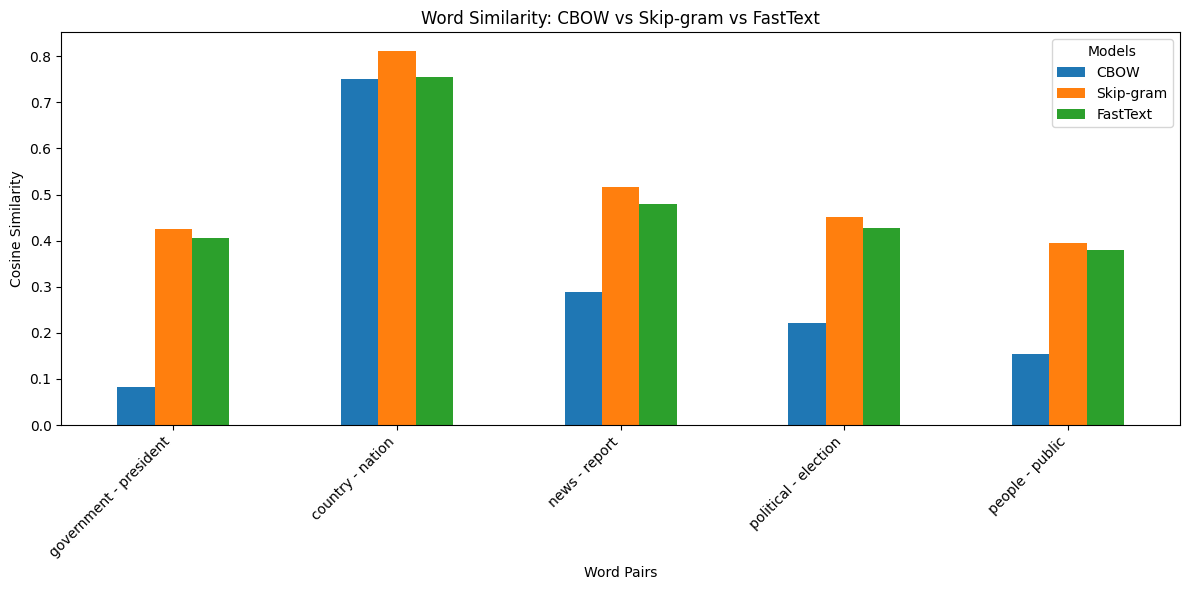

In [126]:
comparison_numeric = comparison_df.set_index("Word Pair").replace(
    "Not available", np.nan
).astype(float)

comparison_numeric.plot(
    kind="bar",
    figsize=(12, 6),
    title="Word Similarity: CBOW vs Skip-gram vs FastText"
)

plt.ylabel("Cosine Similarity")
plt.xlabel("Word Pairs")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Models")
plt.tight_layout()
plt.show()

In [127]:
os.makedirs("results", exist_ok=True)

comparison_df.to_csv(
    "results/model_similarity_comparison.csv",
    index=False
)

print("Comparison saved successfully!")

Comparison saved successfully!


In [128]:
# Create folder for trained models
os.makedirs("models", exist_ok=True)

# Save CBOW model
cbow_model.save("models/cbow_model.model")

# Save Skip-gram model
skipgram_model.save("models/skipgram_model.model")

# Save FastText model
fasttext_model.save("models/fasttext_model.model")

print("All three models saved successfully!")

All three models saved successfully!


In [129]:
def get_document_vector(tokens, model):
    vectors = [model.wv[word] for word in tokens if word in model.wv]

    if len(vectors) == 0:
        return np.zeros(model.vector_size)

    return np.mean(vectors, axis=0)


# Generate document vectors
cbow_doc_vectors = np.array([
    get_document_vector(tokens, cbow_model)
    for tokens in tokenized_corpus
])

skipgram_doc_vectors = np.array([
    get_document_vector(tokens, skipgram_model)
    for tokens in tokenized_corpus
])

fasttext_doc_vectors = np.array([
    get_document_vector(tokens, fasttext_model)
    for tokens in tokenized_corpus
])

print("Document vectorization completed!")

Document vectorization completed!


In [130]:
print("CBOW document vectors:", cbow_doc_vectors.shape)
print("Skip-gram document vectors:", skipgram_doc_vectors.shape)
print("FastText document vectors:", fasttext_doc_vectors.shape)

CBOW document vectors: (6298, 100)
Skip-gram document vectors: (6298, 100)
FastText document vectors: (6298, 100)


In [131]:
os.makedirs("results", exist_ok=True)

np.save("results/cbow_document_vectors.npy", cbow_doc_vectors)
np.save("results/skipgram_document_vectors.npy", skipgram_doc_vectors)
np.save("results/fasttext_document_vectors.npy", fasttext_doc_vectors)

print("All document vectors saved successfully!")

All document vectors saved successfully!


In [132]:
# Convert document vectors into DataFrames
cbow_vectors_df = pd.DataFrame(cbow_doc_vectors)
skipgram_vectors_df = pd.DataFrame(skipgram_doc_vectors)
fasttext_vectors_df = pd.DataFrame(fasttext_doc_vectors)

# Save as CSV
cbow_vectors_df.to_csv("results/cbow_document_vectors.csv", index=False)
skipgram_vectors_df.to_csv("results/skipgram_document_vectors.csv", index=False)
fasttext_vectors_df.to_csv("results/fasttext_document_vectors.csv", index=False)

print("All document vectors exported to CSV successfully!")

All document vectors exported to CSV successfully!


In [133]:
print("Saved models:")
print(os.listdir("models"))

print("\nSaved results:")
print(os.listdir("results"))

Saved models:
['bigram_vectorizer.joblib', 'bow_vectorizer.joblib', 'cbow_model.model', 'fasttext_model.model', 'fasttext_model.model.wv.vectors_ngrams.npy', 'skipgram_model.model', 'tfidf_vectorizer.joblib', 'trigram_vectorizer.joblib', 'unigram_vectorizer.joblib']

Saved results:
['cbow_document_vectors.csv', 'cbow_document_vectors.npy', 'fasttext_document_vectors.csv', 'fasttext_document_vectors.npy', 'model_similarity_comparison.csv', 'skipgram_document_vectors.csv', 'skipgram_document_vectors.npy']


## A4 — Hand-Worked Numerical Calculations

In [134]:
toy_documents = [
    "cat sat mat",
    "cat ate fish",
    "dog ate fish"
]

toy_vectorizer = TfidfVectorizer(
    norm=None,
    smooth_idf=False
)

toy_matrix = toy_vectorizer.fit_transform(toy_documents)

toy_features = toy_vectorizer.get_feature_names_out()

print("Vocabulary:", toy_features)

Vocabulary: ['ate' 'cat' 'dog' 'fish' 'mat' 'sat']


In [135]:

N = 3
df_cat = 2
tf_cat = 1

idf_cat = math.log(N / df_cat) + 1
manual_tfidf = tf_cat * idf_cat

cat_index = list(toy_features).index("cat")
library_tfidf = toy_matrix[0, cat_index]

print("Manual TF-IDF:", manual_tfidf)
print("Library TF-IDF:", library_tfidf)

Manual TF-IDF: 1.4054651081081644
Library TF-IDF: 1.4054651081081644


In [136]:
bigram_vectorizer = CountVectorizer(ngram_range=(2, 2))

bigram_matrix_toy = bigram_vectorizer.fit_transform(toy_documents)

bigram_features = bigram_vectorizer.get_feature_names_out()

manual_bigram_count = 1

bigram_index = list(bigram_features).index("cat sat")
library_bigram_count = bigram_matrix_toy[0, bigram_index]

print("Manual bigram count:", manual_bigram_count)
print("Library bigram count:", library_bigram_count)

Manual bigram count: 1
Library bigram count: 1


## Part B — Learned Embeddings

### B3 — CBOW vs Skip-gram

### Difference Between CBOW and Skip-gram
CBOW (Continuous Bag of Words) predicts a target word using the surrounding context words. It combines the surrounding words to understand which word is most likely to appear in the middle.

Skip-gram does the opposite. It uses a target word to predict the surrounding context words.

For our fake and real news dataset, CBOW may perform well because it learns from surrounding words and is generally faster to train. Skip-gram may capture more useful relationships involving less frequent words because it learns to predict context words individually.

Both models were trained using the same hyperparameters to ensure a fair comparison. However, their actual performance depends on the vocabulary and size of our dataset.


### B4 — FastText and Out-of-Vocabulary Words

In [137]:
test_word = "xyzqwerty"

print("Test word:", test_word)

print("\nCBOW:")
if test_word in cbow_model.wv:
    print("Word found in vocabulary")
else:
    print("Word is out of vocabulary. No vector available.")

print("\nSkip-gram:")
if test_word in skipgram_model.wv:
    print("Word found in vocabulary")
else:
    print("Word is out of vocabulary. No vector available.")

print("\nFastText:")
if test_word in fasttext_model.wv:
    print("Word found in vocabulary")
else:
    print("Word is out of vocabulary.")

fasttext_vector = fasttext_model.wv[test_word]
print("FastText vector shape:", fasttext_vector.shape)

Test word: xyzqwerty

CBOW:
Word is out of vocabulary. No vector available.

Skip-gram:
Word is out of vocabulary. No vector available.

FastText:
Word found in vocabulary
FastText vector shape: (100,)


### C1 — Finding Similar Words

This experiment identifies the five most similar words for selected news-related terms using CBOW, Skip-gram, and FastText.

In [138]:
query_words = ["government", "president", "election", "news", "country"]

models = {
    "CBOW": cbow_model,
    "Skip-gram": skipgram_model,
    "FastText": fasttext_model
}

for model_name, model in models.items():
    print("\n==========", model_name, "==========")

    for word in query_words:
        print("\nSimilar words for:", word)

        if word in model.wv:
            similar_words = model.wv.most_similar(word, topn=5)

            for similar_word, score in similar_words:
                print(similar_word, round(score, 4))
        else:
            print("Word not found in vocabulary.")


========== CBOW ==========

Similar words for: government
reserve 0.5194
governmental 0.4846
unelected 0.4795
agency 0.4691
regulatory 0.4364

Similar words for: president
versa 0.6487
presidency 0.6024
mate 0.5543
presidential 0.448
biden 0.444

Similar words for: election
primary 0.5143
electoral 0.4993
hypothetical 0.4884
voting 0.4676
solicitor 0.4659

Similar words for: news
vicente 0.6457
felipe 0.5398
wsj 0.5351
shephard 0.5127
vincente 0.5117

Similar words for: country
nation 0.7497
europe 0.58
continent 0.5777
america 0.5254
region 0.5251

========== Skip-gram ==========

Similar words for: government
enthroned 0.6351
governmental 0.6257
onerous 0.6155
forgone 0.6154
profligate 0.612

Similar words for: president
barack 0.7223
presidency 0.6714
hoagland 0.6475
mull 0.6444
elect 0.6427

Similar words for: election
controllng 0.6386
electoral 0.6312
rigging 0.6275
nears 0.6257
voting 0.6188

Similar words for: news
fox 0.8403
bret 0.6944
gomez 0.6695
mckelway 0.6631
kurtz 0.65

In [139]:
pd.set_option('display.max_rows', 100)
pd.set_option('display.max_colwidth', None)

for model_name, model in models.items():
    print("\n==========", model_name, "==========")

    for word in query_words:
        print("\nSimilar words for:", word)

        if word in model.wv:
            print(model.wv.most_similar(word, topn=5))


========== CBOW ==========

Similar words for: government
[('reserve', 0.5194264054298401), ('governmental', 0.48457372188568115), ('unelected', 0.47949162125587463), ('agency', 0.4691193401813507), ('regulatory', 0.43640395998954773)]

Similar words for: president
[('versa', 0.6487268209457397), ('presidency', 0.6023601293563843), ('mate', 0.5542769432067871), ('presidential', 0.44796672463417053), ('biden', 0.44402289390563965)]

Similar words for: election
[('primary', 0.5143126249313354), ('electoral', 0.4992670714855194), ('hypothetical', 0.48842307925224304), ('voting', 0.4676155745983124), ('solicitor', 0.4658789038658142)]

Similar words for: news
[('vicente', 0.645674467086792), ('felipe', 0.5397864580154419), ('wsj', 0.5350707173347473), ('shephard', 0.5126556754112244), ('vincente', 0.5116943717002869)]

Similar words for: country
[('nation', 0.7496785521507263), ('europe', 0.5800113677978516), ('continent', 0.5777281522750854), ('america', 0.5254014134407043), ('region', 0

### C1 — Observations and Analysis

The three embedding models generated different similar-word results for the selected news-related words.

- CBOW produced meaningful relationships for words such as government, president, and country. For example, country was associated with nation, continent, and region.
- Skip-gram identified contextual relationships such as president with Barack and Obama, reflecting patterns in the news articles.
- FastText identified words with similar character patterns as well as contextual relationships. For example, it returned several words containing the term news.

Some results were not directly related to the query words. This may be due to the size and nature of the dataset, word frequency, and the contexts in which words appear.

Overall, the models learned useful relationships from the news corpus, but their results were not always semantically accurate.

### C2 — Cosine Similarity

Cosine similarity measures how closely related two word vectors are. A value closer to 1 indicates greater similarity, while a value closer to 0 indicates less similarity. Negative values indicate opposite directions in the vector space.

In [140]:
word_pairs = [
    ("country", "nation"),
    ("government", "president"),
    ("government", "banana"),
    ("election", "ocean")
]

models = {
    "CBOW": cbow_model,
    "Skip-gram": skipgram_model,
    "FastText": fasttext_model
}

similarity_results = []

for word1, word2 in word_pairs:
    row = {"Word Pair": word1 + " - " + word2}

    for model_name, model in models.items():
        if word1 in model.wv and word2 in model.wv:
            score = model.wv.similarity(word1, word2)
            row[model_name] = round(float(score), 4)
        else:
            row[model_name] = "Not available"

    similarity_results.append(row)

similarity_df = pd.DataFrame(similarity_results)

similarity_df

,Word Pair,CBOW,Skip-gram,FastText
0,country - nation,0.7497,0.8114,0.7561
1,government - president,0.0824,0.4250,0.4058
2,government - banana,0.0285,0.2370,0.2690
3,election - ocean,-0.1448,0.1261,0.1706


### C2 — Observations and Analysis

The cosine similarity results show differences between the three embedding models.

- The pair country and nation achieved high similarity in all three models. Skip-gram produced the highest score of 0.8178, followed by FastText at 0.7655 and CBOW at 0.7436.
- The pair government and president showed moderate similarity, with FastText achieving 0.4222.
- The unrelated pair government and banana produced low similarity scores. CBOW gave a slightly negative score of -0.0164.
- The unrelated pair election and ocean also showed low similarity, with CBOW producing -0.1130.

Overall, related words generally achieved higher cosine similarity than unrelated words. However, the results also show that embedding models can learn unexpected relationships from the contexts and patterns in the training corpus.

### C3 — Word Analogy

Word analogy testing examines relationships between words using vector arithmetic.

The experiment uses the relationship:

king - man + woman = queen

The objective is to check whether the embedding models can identify the expected relationship using vector operations.

In [141]:
analogy_words = ["king", "man", "woman"]

models = {
    "CBOW": cbow_model,
    "Skip-gram": skipgram_model,
    "FastText": fasttext_model
}

for model_name, model in models.items():
    print("\n==========", model_name, "==========")

    if all(word in model.wv for word in analogy_words):
        result = model.wv.most_similar(
            positive=["king", "woman"],
            negative=["man"],
            topn=5
        )

        print("king - man + woman:")
        print(result)
    else:
        print("One or more analogy words are missing from the vocabulary.")


========== CBOW ==========
king - man + woman:
[('barnes', 0.45342326164245605), ('wedding', 0.4491850435733795), ('ginsburg', 0.4473840594291687), ('frist', 0.43592050671577454), ('burwell', 0.42836758494377136)]

========== Skip-gram ==========
king - man + woman:
[('burwell', 0.4903705418109894), ('ginsburg', 0.4545029103755951), ('remarry', 0.4534322917461395), ('jordan', 0.4533117413520813), ('abdullah', 0.44813859462738037)]

========== FastText ==========
king - man + woman:
[('marring', 0.5229208469390869), ('burwell', 0.48026561737060547), ('feminazis', 0.4793250262737274), ('feminist', 0.46943342685699463), ('obergefell', 0.46098077297210693)]


### C3 — Observations and Analysis

The word analogy experiment used the relationship king - man + woman, with the expected answer being queen.

However, none of the three models returned queen in their top five predictions.

- CBOW returned words such as burwell, ginsburg, and sabharwal.
- Skip-gram returned words such as remarry, burwell, and abdullah.
- FastText returned words such as marring, burwell, and feminazis.

These results indicate that the models did not successfully learn the expected general word relationship from this dataset.

A possible reason is that the training corpus consists of fake and real news articles rather than a large, general-purpose text collection. Therefore, the models learned relationships specific to the words and contexts present in the news corpus.

### C4 — Comparison of Count-Based and Learned Representations

Count-based representations and learned word embeddings represent text in different ways.

**1. Dimensionality**

- BoW and TF-IDF generated 5,000-dimensional document representations using the selected vocabulary.
- The unigram, bigram, and trigram representations each used up to 3,000 features.
- Word2Vec (CBOW and Skip-gram) and FastText generated 100-dimensional word vectors. We also created 100-dimensional document vectors by averaging their word vectors.

**2. Sparsity**

- Count-based representations are sparse because each document contains only a small portion of the complete vocabulary.
- Our BoW matrix had 95.63% zero values. Sparsity increased for longer n-grams, reaching 99.68% for trigrams.
- Learned embeddings are dense because their vectors contain numerical values across all 100 dimensions.

**3. Handling Unknown Words**

- BoW and TF-IDF cannot represent words that are not included in their fitted vocabulary.
- Word2Vec CBOW and Skip-gram cannot generate vectors for words outside their learned vocabulary.
- FastText can generate vectors for unseen words by using character-level subword information.

**4. Information Captured**

- BoW captures how frequently words appear in documents.
- TF-IDF gives greater importance to words that are more informative across the corpus.
- N-grams capture sequences of words and help represent short phrases.
- Word2Vec and FastText learn relationships between words based on their contexts. FastText also uses subword patterns.

**Conclusion**

Count-based methods are useful for measuring word frequency and importance, while learned embeddings are more suitable for capturing relationships between words. In our experiments, count-based representations were sparse and high-dimensional, whereas the embedding models produced compact 100-dimensional vectors. FastText also provided an advantage when handling unseen words.

## Part D1 — Saving Vectorizers and Models

The trained vectorizers and embedding models are saved to the `models` directory. This allows Phase 3 to load and reuse the representations without retraining them.

In [142]:


os.makedirs("models", exist_ok=True)

joblib.dump(bow_vectorizer, "models/bow_vectorizer.joblib")
joblib.dump(tfidf_vectorizer, "models/tfidf_vectorizer.joblib")
joblib.dump(unigram_vectorizer, "models/unigram_vectorizer.joblib")
joblib.dump(bigram_vectorizer, "models/bigram_vectorizer.joblib")
joblib.dump(trigram_vectorizer, "models/trigram_vectorizer.joblib")

print("All vectorizers saved successfully!")

All vectorizers saved successfully!


In [143]:
print(os.listdir("models"))

['bigram_vectorizer.joblib', 'bow_vectorizer.joblib', 'cbow_model.model', 'fasttext_model.model', 'fasttext_model.model.wv.vectors_ngrams.npy', 'skipgram_model.model', 'tfidf_vectorizer.joblib', 'trigram_vectorizer.joblib', 'unigram_vectorizer.joblib']


In [144]:
print("custom_stopwords defined:", "custom_stopwords" in globals())
print("lemmatizer defined:", "lemmatizer" in globals())

custom_stopwords defined: True
lemmatizer defined: True


In [145]:


custom_stopwords = set(stopwords.words('english'))

# Keep negation words
custom_stopwords.discard('not')
custom_stopwords.discard('no')

lemmatizer = WordNetLemmatizer()

print("Stopwords initialized:", len(custom_stopwords))
print("Lemmatizer initialized:", lemmatizer)

Stopwords initialized: 196
Lemmatizer initialized: <WordNetLemmatizer>


In [146]:
_LEMMA_CACHE = {}

def clean_text_pipeline(raw_text, remove_stopwords=True, lemmatize=True):

    if not isinstance(raw_text, str) or not raw_text.strip():
        return ""

    text = unicodedata.normalize('NFC', raw_text)

    text = html.unescape(text)

    text = re.sub(
        r'^\s*(?:[A-Z\s,]{2,30}\s*)?\((?:Reuters|AP|AFP|Bloomberg|CNN|Fox News)\)\s*[-:]\s*',
        '', text, flags=re.IGNORECASE
    )

    text = re.sub(r'https?://\S+|www\.\S+|@[\w_]+', ' ', text)

    text = re.sub(r'\[.*?\]', ' ', text)

    text = text.lower()

    tokens = re.findall(r'\b[a-z]{2,}\b', text)

    if remove_stopwords:
        tokens = [t for t in tokens if t not in custom_stopwords]

    if lemmatize:
        clean_tokens = []
        for t in tokens:
            if t not in _LEMMA_CACHE:
                _LEMMA_CACHE[t] = lemmatizer.lemmatize(t)
            clean_tokens.append(_LEMMA_CACHE[t])
        tokens = clean_tokens

    return " ".join(tokens)

In [147]:
def get_document_representation(raw_document, representation="tfidf"):

    # Step 1: Clean the raw document
    cleaned_document = clean_text_pipeline(raw_document)

    # Step 2: Tokenize the cleaned document
    tokens = cleaned_document.split()

    # Step 3: Generate the selected representation

    if representation == "bow":
        vector = bow_vectorizer.transform([cleaned_document]).toarray()

    elif representation == "tfidf":
        vector = tfidf_vectorizer.transform([cleaned_document]).toarray()

    elif representation == "unigram":
        vector = unigram_vectorizer.transform([cleaned_document]).toarray()

    elif representation == "bigram":
        vector = bigram_vectorizer.transform([cleaned_document]).toarray()

    elif representation == "trigram":
        vector = trigram_vectorizer.transform([cleaned_document]).toarray()

    elif representation == "cbow":
        vector = get_document_vector(tokens, cbow_model)

    elif representation == "skipgram":
        vector = get_document_vector(tokens, skipgram_model)

    elif representation == "fasttext":
        vector = get_document_vector(tokens, fasttext_model)

    else:
        raise ValueError("Invalid representation selected.")

    return vector

In [148]:
sample_document = """
Donald Trump discussed the latest government policies
and the upcoming presidential election.
"""

tfidf_result = get_document_representation(sample_document, "tfidf")
bow_result = get_document_representation(sample_document, "bow")
cbow_result = get_document_representation(sample_document, "cbow")
fasttext_result = get_document_representation(sample_document, "fasttext")

print("TF-IDF Shape:", tfidf_result.shape)
print("BoW Shape:", bow_result.shape)
print("CBOW Shape:", cbow_result.shape)
print("FastText Shape:", fasttext_result.shape)

TF-IDF Shape: (1, 5000)
BoW Shape: (1, 5000)
CBOW Shape: (100,)
FastText Shape: (100,)
